# 08 · XGBoost Tuning

**What this notebook covers**

- Search space and randomised search with 5-fold CV on Train
- Search diagnostics: score distribution, parameter sensitivity, top candidates
- Final refit with early stopping on Dev
- Learning curve
- Gain-based feature importance
- Error examples on Dev

## 1. Environment setup
### 1.1 Imports
Standard model-notebook imports plus the estimator-specific ones.

In [3]:
import hashlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score, brier_score_loss, f1_score, make_scorer,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier

### 1.2 Configuration
Every tunable knob lives here. Lower the search budget for a quick dry run, but use
the defaults for the reported results.

In [4]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "08"
NOTEBOOK_NAME = "08_xgboost_tuning.ipynb"
CV_FOLDS = 5

VARIANTS = ["day_zero", "full_lifecycle"]
N_ITER = 50
EARLY_STOPPING_ROUNDS = 50
MAX_BOOSTING_ROUNDS = 3000

### 1.3 Project paths, shared constants and helpers

In [5]:
# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


In [6]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [7]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

In [8]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,3.2.0
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,not installed


## 2. Load Train and Dev features (contract-verified)
Inputs are hash-checked against `feature_spec.json`. The held-out evaluation split is
deliberately not loaded here.

In [9]:
# Load the shared feature contract and ONLY the Train and Dev feature files.
# The held-out split is intentionally never referenced in model notebooks
# (the validation gate in notebook 10 scans this notebook's source to prove it).
FEATURE_SPEC = load_json(PATHS["artifacts"] / "feature_spec.json")

TRAIN_PATH = PATHS["features"] / "train.csv"
DEV_PATH = PATHS["features"] / "dev.csv"
DATA_FILES_READ = [str(TRAIN_PATH.relative_to(PROJECT_ROOT)), str(DEV_PATH.relative_to(PROJECT_ROOT))]

INPUT_HASHES = {"train": sha256_file(TRAIN_PATH), "dev": sha256_file(DEV_PATH)}
for split_name, digest in INPUT_HASHES.items():
    expected = FEATURE_SPEC["file_hashes"][split_name]
    assert digest == expected, (
        f"{split_name} feature file hash mismatch - re-run notebook 04 before training models."
    )

train_df = read_frame(TRAIN_PATH)
dev_df = read_frame(DEV_PATH)

X_train = train_df.drop(columns=[TARGET, ID_COLUMN])
y_train = train_df[TARGET].astype(int)
X_dev = dev_df.drop(columns=[TARGET, ID_COLUMN])
y_dev = dev_df[TARGET].astype(int)
dev_ids = dev_df[ID_COLUMN]

assert not set(LEAKAGE_COLUMNS) & set(X_train.columns), "Leakage columns reached the model inputs."
print(f"Train: {X_train.shape}, positive rate {y_train.mean():.4f}")
print(f"Dev:   {X_dev.shape}, positive rate {y_dev.mean():.4f}")

Train: (60996, 38), positive rate 0.2728
Dev:   (13071, 38), positive rate 0.2727


### 2.1 Shared model-notebook helpers
These do the same job in notebooks 05–09: the CV splitter, multi-metric scoring
(refit on PR-AUC), fold-score extraction and `persist_model_outputs`, which writes the
model card contract consumed by the validation gate and the evaluation notebooks.

In [10]:
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCALE_POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())


def build_scoring(include_probability_metrics: bool = True) -> dict:
    """Multi-metric scoring used by every model notebook (refit metric = PR-AUC)."""
    scoring = {
        "pr_auc": "average_precision",
        "roc_auc": "roc_auc",
        "f1": make_scorer(f1_score, zero_division=0),
        "precision": make_scorer(precision_score, zero_division=0),
        "recall": make_scorer(recall_score, zero_division=0),
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy",
    }
    if include_probability_metrics:
        scoring["neg_brier"] = "neg_brier_score"
    return scoring


def load_preprocessor(family: str, variant: str):
    """Load an UNFITTED preprocessing template produced by notebook 04."""
    path = PATHS["preprocessors"] / f"preprocessor__{family}__{variant}.joblib"
    return clone(joblib.load(path))


def make_pipeline(estimator, family: str, variant: str) -> Pipeline:
    return Pipeline([("preprocess", load_preprocessor(family, variant)), ("model", estimator)])


def fold_scores_from_search(search, n_splits: int) -> pd.DataFrame:
    """Per-fold CV scores of the best candidate, read from cv_results_ (no refit needed)."""
    results, best = search.cv_results_, search.best_index_
    metrics = sorted({key.split("_test_", 1)[1] for key in results if key.startswith("split0_test_")})
    rows = []
    for fold in range(n_splits):
        row = {"fold": fold}
        for metric in metrics:
            row[metric] = results[f"split{fold}_test_{metric}"][best]
            train_key = f"split{fold}_train_{metric}"
            if train_key in results:
                row[f"train_{metric}"] = results[train_key][best]
        rows.append(row)
    return tidy_fold_scores(pd.DataFrame(rows))


def fold_scores_from_cross_validate(cv_output: dict) -> pd.DataFrame:
    frame = pd.DataFrame({
        key.replace("test_", "", 1) if key.startswith("test_") else key: values
        for key, values in cv_output.items() if key.startswith(("test_", "train_"))
    })
    frame.insert(0, "fold", range(len(frame)))
    return tidy_fold_scores(frame)


def tidy_fold_scores(frame: pd.DataFrame) -> pd.DataFrame:
    for prefix in ("", "train_"):
        if f"{prefix}neg_brier" in frame:
            frame[f"{prefix}brier"] = -frame.pop(f"{prefix}neg_brier")
    return frame


def summarise_folds(fold_scores: pd.DataFrame) -> dict:
    metric_cols = [c for c in fold_scores.columns if c != "fold" and not c.startswith("train_")]
    return {m: {"mean": float(fold_scores[m].mean()), "std": float(fold_scores[m].std(ddof=1))} for m in metric_cols}


def quick_dev_metrics(y_true, y_proba) -> dict:
    """Lightweight sanity metrics only - the official evaluation happens in notebook 11."""
    return {
        "pr_auc": float(average_precision_score(y_true, y_proba)),
        "roc_auc": float(roc_auc_score(y_true, y_proba)),
        "brier": float(brier_score_loss(y_true, y_proba)),
    }


def persist_model_outputs(*, model_key, variant, family, pipeline, fold_scores, dev_proba,
                          best_params, imbalance_strategy, fit_seconds, search=None,
                          cv_rows=None, extra=None) -> dict:
    """Write the model + the standard model-card contract consumed by notebooks 10-14."""
    model_id = f"{model_key}__{variant}"
    out_dir = PATHS["model_outputs"] / model_id
    out_dir.mkdir(parents=True, exist_ok=True)

    model_path = PATHS["models"] / f"{model_id}.joblib"
    joblib.dump(pipeline, model_path)

    fold_scores.to_csv(out_dir / "cv_fold_scores.csv", index=False)
    pd.DataFrame({ID_COLUMN: dev_ids.values, "y_true": y_dev.values, "y_proba": dev_proba}).to_csv(
        out_dir / "dev_predictions.csv", index=False
    )
    if search is not None:
        pd.DataFrame(search.cv_results_).drop(columns=["params"], errors="ignore").to_csv(
            out_dir / "search_results.csv", index=False
        )

    card = {
        "model_id": model_id,
        "model_key": model_key,
        "variant": variant,
        "notebook": NOTEBOOK_NAME,
        "preprocessor_family": family,
        "imbalance_strategy": imbalance_strategy,
        "cv": {
            "type": type(CV).__name__,
            "n_splits": CV.get_n_splits(),
            "shuffle": bool(CV.shuffle),
            "random_state": CV.random_state,
            "n_rows": int(cv_rows if cv_rows is not None else len(X_train)),
        },
        "n_fit_rows": int(len(X_train)),
        "n_dev_rows": int(len(X_dev)),
        "data_files_read": DATA_FILES_READ,
        "input_hashes": INPUT_HASHES,
        "best_params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in best_params.items()},
        "cv_summary": summarise_folds(fold_scores),
        "dev_quick": quick_dev_metrics(y_dev, dev_proba),
        "fit_seconds": round(float(fit_seconds), 2),
        "model_path": str(model_path.relative_to(PROJECT_ROOT)),
        "model_sha256": sha256_file(model_path),
        "random_state": RANDOM_STATE,
        "library_versions": LIBRARY_VERSIONS,
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        **(extra or {}),
    }
    save_json(card, out_dir / "model_card.json")
    print(f"[{model_id}] CV PR-AUC {card['cv_summary']['pr_auc']['mean']:.4f} "
          f"± {card['cv_summary']['pr_auc']['std']:.4f} | Dev PR-AUC {card['dev_quick']['pr_auc']:.4f}")
    return card

## 3. Search space
Seven parameters: the six required ones plus `scale_pos_weight`. The imbalance weight
is *searched* (1 vs the Train neg/pos ratio) rather than fixed, so the evidence for
decision #7 comes from data. Continuous parameters use continuous distributions,
which random search explores better than a coarse grid.

In [11]:
XGB_SPACE = {
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__max_depth": randint(3, 11),
    "model__n_estimators": randint(200, 1001),
    "model__subsample": uniform(0.6, 0.4),          # U(0.6, 1.0)
    "model__colsample_bytree": uniform(0.5, 0.5),   # U(0.5, 1.0)
    "model__min_child_weight": loguniform(1, 20),
    "model__scale_pos_weight": [1.0, SCALE_POS_WEIGHT],
}


def base_xgb(**overrides) -> XGBClassifier:
    params = dict(objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
                  n_jobs=-1, random_state=RANDOM_STATE, verbosity=0)
    params.update(overrides)
    return XGBClassifier(**params)

print(f"Train scale_pos_weight (neg/pos): {SCALE_POS_WEIGHT:.3f}")

Train scale_pos_weight (neg/pos): 2.666


## 4. Randomised search inside Train-only CV
The search object only ever receives `X_train` / `y_train`. Notebook 10 verifies this
from the model card and by scanning this notebook's source.

In [12]:
xgb_searches = {}
for variant in VARIANTS:
    pipeline = make_pipeline(base_xgb(), "tree", variant)
    search = RandomizedSearchCV(pipeline, XGB_SPACE, n_iter=N_ITER, scoring=build_scoring(), refit="pr_auc", cv=CV,
                                n_jobs=1, random_state=RANDOM_STATE, return_train_score=True)
    start = time.perf_counter()
    search.fit(X_train, y_train)
    search.elapsed_seconds_ = time.perf_counter() - start
    xgb_searches[variant] = search
    print(f"[{variant}] best CV PR-AUC {search.best_score_:.4f} ({search.elapsed_seconds_ / 60:.1f} min)")
    print(f"          best params {search.best_params_}")

[day_zero] best CV PR-AUC 0.7654 (9.3 min)
          best params {'model__colsample_bytree': np.float64(0.8604699621260646), 'model__learning_rate': np.float64(0.02851301505515497), 'model__max_depth': 10, 'model__min_child_weight': np.float64(1.3239563983335276), 'model__n_estimators': 669, 'model__scale_pos_weight': 1.0, 'model__subsample': np.float64(0.7001847274422337)}
[full_lifecycle] best CV PR-AUC 0.8047 (9.7 min)
          best params {'model__colsample_bytree': np.float64(0.8604699621260646), 'model__learning_rate': np.float64(0.02851301505515497), 'model__max_depth': 10, 'model__min_child_weight': np.float64(1.3239563983335276), 'model__n_estimators': 669, 'model__scale_pos_weight': 1.0, 'model__subsample': np.float64(0.7001847274422337)}


## 5. Search diagnostics
### 5.1 Distribution of CV PR-AUC across all candidates
A narrow distribution means XGBoost is robust to its hyper-parameters on this data. A
wide one means tuning matters and the best point might be partly luck.

Saved figure -> reports/figures/08_search_score_distribution.png


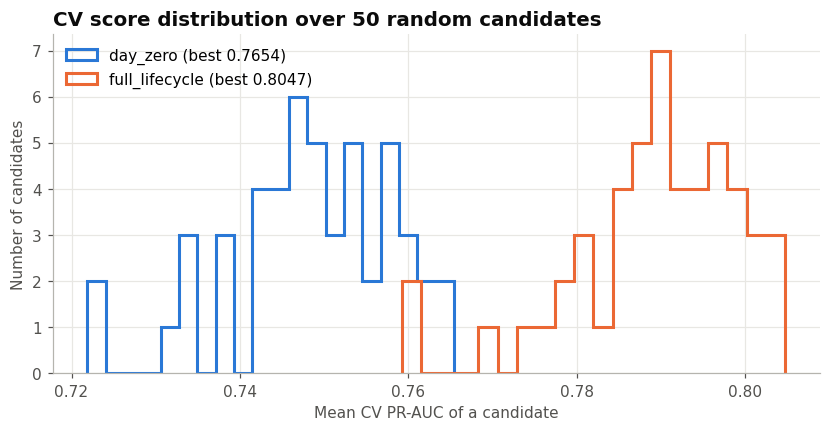

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
for color, (variant, search) in zip(SERIES_COLORS, xgb_searches.items()):
    scores = pd.Series(search.cv_results_["mean_test_pr_auc"])
    ax.hist(scores, bins=20, histtype="step", linewidth=2, color=color, label=f"{variant} (best {scores.max():.4f})")
ax.set_xlabel("Mean CV PR-AUC of a candidate")
ax.set_ylabel("Number of candidates")
ax.set_title(f"CV score distribution over {N_ITER} random candidates", loc="left")
ax.legend()
save_figure(fig, "search_score_distribution")
plt.show()

### 5.2 Sensitivity to the two most influential parameters
Each dot is one candidate (day-zero). The colour is its CV PR-AUC on a single-hue
sequential scale.

Saved figure -> reports/figures/08_search_sensitivity.png


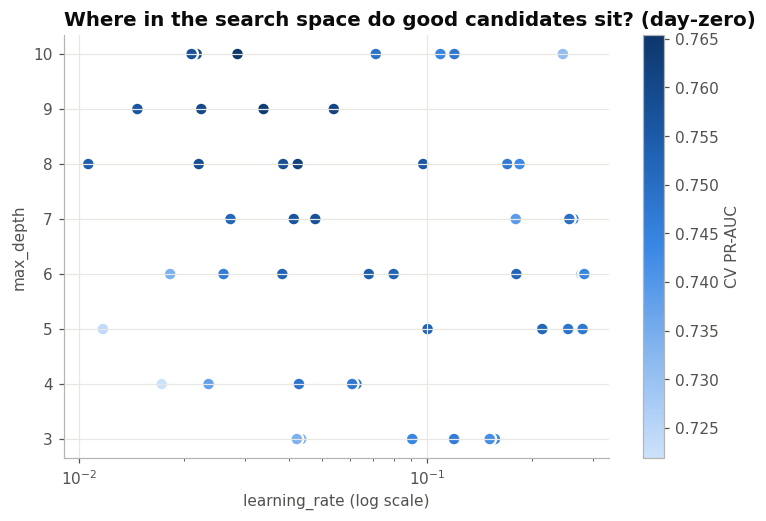

In [14]:
results = pd.DataFrame(xgb_searches["day_zero"].cv_results_)
fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(results["param_model__learning_rate"].astype(float), results["param_model__max_depth"].astype(int),
                    c=results["mean_test_pr_auc"], cmap=SEQUENTIAL_CMAP, s=70, edgecolor="white", linewidth=1.5)
ax.set_xscale("log")
ax.set_xlabel("learning_rate (log scale)")
ax.set_ylabel("max_depth")
ax.set_title("Where in the search space do good candidates sit? (day-zero)", loc="left")
fig.colorbar(points, ax=ax, label="CV PR-AUC")
save_figure(fig, "search_sensitivity")
plt.show()

### 5.3 Top-10 candidates table

In [15]:
param_cols = [c for c in results.columns if c.startswith("param_")]
top10 = results.sort_values("rank_test_pr_auc").head(10)[["rank_test_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_train_pr_auc", *param_cols]]
top10.to_csv(PATHS["tables"] / "08_xgboost_day_zero_top10_candidates.csv", index=False)
top10.round(4)

,rank_test_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_train_pr_auc,param_model__colsample_bytree,param_model__learning_rate,param_model__max_depth,param_model__min_child_weight,param_model__n_estimators,param_model__scale_pos_weight,param_model__subsample
39,1,0.7654,0.0021,0.9599,0.8605,0.0285,10,1.3240,669,1.0000,0.7002
46,2,0.7636,0.0026,0.9057,0.8356,0.0339,9,4.7246,585,2.6663,0.8963
8,3,0.7627,0.0023,0.8990,0.8777,0.0425,8,5.1438,676,1.0000,0.9369
7,4,0.7613,0.0030,0.8927,0.5610,0.0539,9,1.6809,280,2.6663,0.6729
19,5,0.7606,0.0021,0.8632,0.8778,0.0218,10,6.0137,442,2.6663,0.9522
28,6,0.7599,0.0022,0.8724,0.8808,0.0224,9,11.0894,809,2.6663,0.7595
45,7,0.7595,0.0026,0.9003,0.6863,0.0383,8,8.0455,885,2.6663,0.6836
4,8,0.7585,0.0020,0.8463,0.9869,0.0221,8,10.5084,762,2.6663,0.8057
49,9,0.7582,0.0027,0.8457,0.5355,0.0386,8,14.3855,670,1.0000,0.7502
1,10,0.7578,0.0017,0.8781,0.5500,0.0477,7,6.0544,863,1.0000,0.6082


## 6. Final refit with early stopping on Dev
### 6.1 Refit per variant
1. Fit the preprocessor on Train only.
2. Transform Train and Dev with it.
3. Fit XGBoost with the best parameters and a large round budget, stopping when Dev
   `aucpr` stops improving.
4. Assemble `Pipeline([fitted preprocessor, fitted booster])`, the same interface as
   every other model.

The CV fold scores logged for this model are those of the searched configuration
(fixed `n_estimators`). Early stopping only adjusts the number of rounds.

In [16]:
xgb_final, xgb_cards = {}, {}
for variant, search in xgb_searches.items():
    best_model_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    best_model_params.pop("n_estimators")

    preprocessor = load_preprocessor("tree", variant).fit(X_train, y_train)
    train_matrix, dev_matrix = preprocessor.transform(X_train), preprocessor.transform(X_dev)

    booster = base_xgb(**best_model_params, n_estimators=MAX_BOOSTING_ROUNDS, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
    start = time.perf_counter()
    booster.fit(train_matrix, y_train, eval_set=[(train_matrix, y_train), (dev_matrix, y_dev)], verbose=False)
    refit_seconds = time.perf_counter() - start

    final_pipeline = Pipeline([("preprocess", preprocessor), ("model", booster)])
    xgb_final[variant] = final_pipeline
    print(f"[{variant}] best iteration {booster.best_iteration} (Dev aucpr {booster.best_score:.4f})")

    xgb_cards[variant] = persist_model_outputs(
        model_key="xgboost", variant=variant, family="tree", pipeline=final_pipeline,
        fold_scores=fold_scores_from_search(search, CV_FOLDS),
        dev_proba=final_pipeline.predict_proba(X_dev)[:, 1],
        best_params=search.best_params_, imbalance_strategy="scale_pos_weight (searched)",
        fit_seconds=search.elapsed_seconds_ + refit_seconds, search=search,
        extra={"best_iteration": int(booster.best_iteration), "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
               "early_stopping_set": "dev", "scale_pos_weight_reference": SCALE_POS_WEIGHT},
    )

[day_zero] best iteration 610 (Dev aucpr 0.7707)
[xgboost__day_zero] CV PR-AUC 0.7654 ± 0.0023 | Dev PR-AUC 0.7707
[full_lifecycle] best iteration 588 (Dev aucpr 0.8124)
[xgboost__full_lifecycle] CV PR-AUC 0.8047 ± 0.0025 | Dev PR-AUC 0.8124


### 6.2 Learning curve (day-zero)
Train vs Dev `aucpr` by boosting round. The vertical line marks the early-stopping
point. A widening gap after it is the over-fitting that early stopping prevents.

Saved figure -> reports/figures/08_learning_curve.png


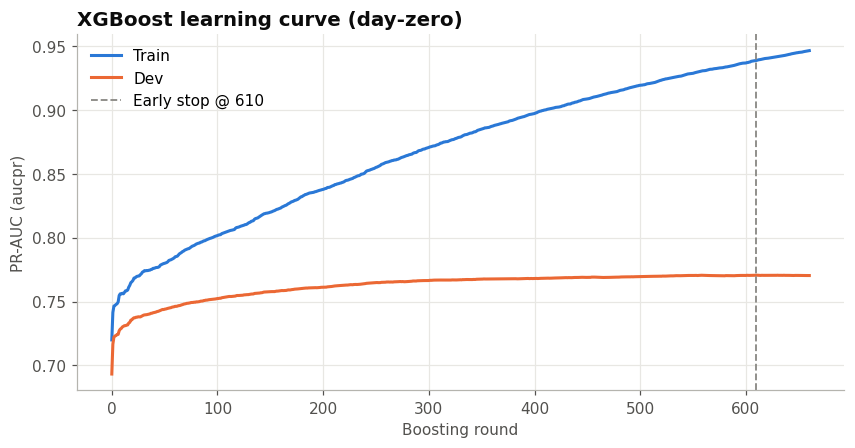

In [17]:
booster = xgb_final["day_zero"].named_steps["model"]
history = booster.evals_result()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(history["validation_0"]["aucpr"], color=SERIES_COLORS[0], label="Train")
ax.plot(history["validation_1"]["aucpr"], color=SERIES_COLORS[1], label="Dev")
ax.axvline(booster.best_iteration, color=COLORS["neutral"], linestyle="--", linewidth=1.2,
           label=f"Early stop @ {booster.best_iteration}")
ax.set_xlabel("Boosting round")
ax.set_ylabel("PR-AUC (aucpr)")
ax.set_title("XGBoost learning curve (day-zero)", loc="left")
ax.legend()
save_figure(fig, "learning_curve")
plt.show()

## 7. Gain-based feature importance (day-zero)
Gain is the average loss reduction from splits on a feature. Notebook 13 compares it with
SHAP in notebook 13.

Saved figure -> reports/figures/08_gain_importance.png


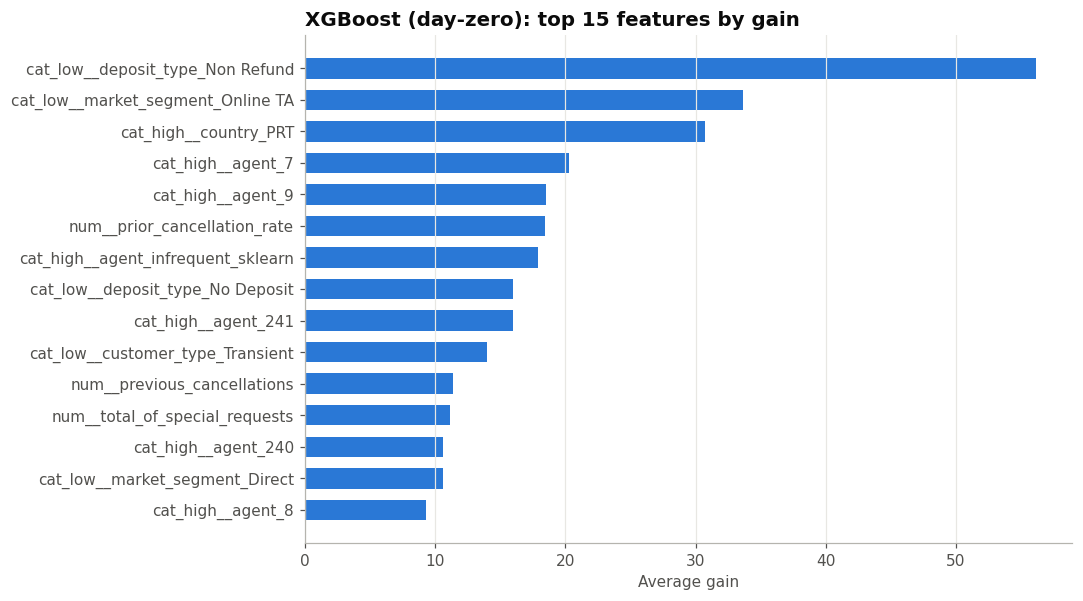

In [18]:
names = xgb_final["day_zero"].named_steps["preprocess"].get_feature_names_out()
gain = booster.get_booster().get_score(importance_type="gain")
gain_importance = pd.Series({names[int(k[1:])]: v for k, v in gain.items()}, name="gain").sort_values(ascending=False)
gain_importance.to_csv(PATHS["tables"] / "08_xgboost_day_zero_gain_importance.csv")

top = gain_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=COLORS["not_canceled"], height=0.65)
ax.set_xlabel("Average gain")
ax.set_title("XGBoost (day-zero): top 15 features by gain", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "gain_importance")
plt.show()

## 8. Error examples for comparison with Random Forest (Dev, threshold 0.5)
The most confident mistakes are the most informative ones. They are exported for the
error-profile comparison in notebook 13. The 0.5 threshold is only a convention here;
the operational threshold is set in notebook 12.

In [19]:
dev_view = dev_df[[ID_COLUMN, "hotel", "market_segment", "deposit_type", "lead_time", "customer_type"]].copy()
dev_view["y_true"] = y_dev.values
dev_view["y_proba"] = xgb_final["day_zero"].predict_proba(X_dev)[:, 1]
false_negatives = dev_view[(dev_view["y_true"] == 1) & (dev_view["y_proba"] < 0.5)].nsmallest(15, "y_proba")
false_positives = dev_view[(dev_view["y_true"] == 0) & (dev_view["y_proba"] >= 0.5)].nlargest(15, "y_proba")
pd.concat({"false_negative": false_negatives, "false_positive": false_positives}).to_csv(
    PATHS["tables"] / "08_xgboost_day_zero_error_examples.csv")
print(f"FN at 0.5: {((dev_view['y_true'] == 1) & (dev_view['y_proba'] < 0.5)).sum():,} | "
      f"FP at 0.5: {((dev_view['y_true'] == 0) & (dev_view['y_proba'] >= 0.5)).sum():,}")
false_negatives.head(8)

FN at 0.5: 1,292 | FP at 0.5: 876


,booking_id,hotel,market_segment,deposit_type,lead_time,customer_type,y_true,y_proba
222,1525,Resort Hotel,Groups,No Deposit,4,Transient-Party,1,0.003010
6609,58478,City Hotel,Groups,No Deposit,28,Transient-Party,1,0.003305
7460,70258,City Hotel,Offline TA/TO,No Deposit,22,Transient,1,0.003616
1176,10726,Resort Hotel,Online TA,No Deposit,40,Transient,1,0.006574
8111,78577,City Hotel,Corporate,No Deposit,1,Transient,1,0.006902
8475,82712,City Hotel,Direct,No Deposit,1,Transient,1,0.007443
2256,19823,Resort Hotel,Offline TA/TO,No Deposit,23,Transient,1,0.008418
8158,78962,City Hotel,Corporate,No Deposit,0,Transient,1,0.008669


## 9. Hand-off summary
- `xgboost__day_zero` and `xgboost__full_lifecycle` are logged, with full `search_results.csv` and the early-stopping iteration in the model card.
- Gain importance and error examples are in `reports/tables/08_*` for notebook 13.
- Seed used throughout: `RANDOM_STATE = 42`. The search object only ever saw Train data.